# Compare the two approch of identifing the RFI

## VM2R
-> I have to perform the variance for each time stemp, the plot the Var over frequency

-> The compare the response of each peak when we apply the median square


In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib import cm, colors as mcolors
import matplotlib.ticker as mticker
from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting



# import imageio # to collect frames and write them into an animated file.
import os
# from PIL import Image
# import io

import scienceplots
plt.style.use(['science', 'no-latex'])


import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Patch



#from concurrent.futures import ProcessPoolExecutor


In [2]:
# The functions 

# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=16)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=16)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()



            plt.savefig(
            f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.png",
            dpi=300,
            bbox_inches="tight"
        )

            plt.savefig(
                f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.pdf",
                dpi=300,
                bbox_inches="tight"
            )



    return results_outliers


# RFI mask

def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask


# Compute VM^2R for single-dish data
def variance_to_median_square_ratio_single_dish(
    obj,
    time_dim: str = "time",
    freq_dim: str = "freq",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Compute the variance-to-median-square ratio (VM^2R) over time for a
    single-dish dataset.

    Parameters
    ----------
    obj : xr.DataArray or xr.Dataset
        Input dynamic spectrum. If a Dataset is provided, the first data variable
        is used. Expected dimensions include time and frequency, and optionally
        polarization.
    time_dim : str, optional
        Name of the time dimension. Default is "time".
    freq_dim : str, optional
        Name of the frequency dimension. Default is "freq".
    pol_dim : str or None, optional
        Name of the polarization/feed dimension, if present. If None, the
        function assumes no extra per-feed/pol dimension. Default is None.
    eps : float, optional
        Small positive floor used to avoid division by zero. Default is 1e-12.

    Returns
    -------
    xr.Dataset
        Contains:
        - median: time-median per (freq[, pol])
        - variance: time-variance per (freq[, pol])
        - vm2r: variance / median^2 per (freq[, pol])
        - vm2r_by_freq: median VM^2R over polarization/feed (if pol_dim exists),
                        otherwise same as vm2r
        - vm2r_by_pol: median VM^2R over frequency (if pol_dim exists)
        - vm2r_global: global median VM^2R

    Notes
    -----
    VM^2R = Var(X) / Median(X)^2

    For single-dish total-power data this is useful for flagging non-stationary,
    bursty, or RFI-like behaviour in the time-frequency plane.
    """
    # Handle Dataset vs DataArray
    if isinstance(obj, xr.Dataset):
        var_name = list(obj.data_vars)[0]
        data_da = obj[var_name]
    else:
        data_da = obj

    # Check required dims
    required_dims = {time_dim, freq_dim}
    missing = required_dims - set(data_da.dims)
    if missing:
        raise ValueError(f"Input is missing required dimensions: {missing}")

    if pol_dim is not None and pol_dim not in data_da.dims:
        raise ValueError(f"pol_dim='{pol_dim}' not found in input dimensions {data_da.dims}")

    # Compute time statistics
    x = data_da.chunk({time_dim: -1})
    time_median = x.median(dim=time_dim, skipna=True).rename("median")
    time_variance = x.var(dim=time_dim, skipna=True).rename("variance")

    # VM^2R
    denom = time_median**2
    vm2r = (time_variance / denom).rename("vm2r")
    vm2r = vm2r.where(np.abs(time_median) > eps)

    out = {
        "median": time_median,
        "variance": time_variance,
        "vm2r": vm2r,
    }

    # 1D summaries
    if pol_dim is not None:
        vm2r_by_pol = (
            vm2r.chunk({freq_dim: -1})
            .median(dim=freq_dim, skipna=True)
            .rename("vm2r_by_pol")
        )
        vm2r_by_freq = (
            vm2r.chunk({pol_dim: -1})
            .median(dim=pol_dim, skipna=True)
            .rename("vm2r_by_freq")
        )
        out["vm2r_by_pol"] = vm2r_by_pol
        out["vm2r_by_freq"] = vm2r_by_freq
    else:
        out["vm2r_by_freq"] = vm2r.rename("vm2r_by_freq")

    # Global median
    vm2r_global = xr.DataArray(
        np.nanmedian(vm2r.compute().values),
        name="vm2r_global"
    )
    out["vm2r_global"] = vm2r_global

    return xr.Dataset(out)

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [3]:
# DATA
filename = "EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# # Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False

In [4]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e9
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [5]:
datasets.keys()

dict_keys(['scan/000/P1_ND0', 'scan/000/P1_ND1', 'scan/001/P0_ND0', 'scan/001/P0_ND1', 'scan/001/P1_ND0', 'scan/001/P1_ND1'])

In [6]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 164MB
Dimensions:           (time: 638, frequency: 63877, integration_time: 638,
                       ra: 638, dec: 638, elevation: 638, azimuth: 638)
Coordinates:
  * time              (time) float64 5kB 1.682e+09 1.682e+09 ... 1.682e+09
  * frequency         (frequency) float64 511kB 1.793 1.793 ... 3.498 3.498
  * integration_time  (integration_time) float64 5kB 0.1152 0.1135 ... 0.1159
  * ra                (ra) float64 5kB 84.48 84.46 84.45 ... 86.42 86.43 86.43
  * dec               (dec) float64 5kB -3.161 -3.144 -3.135 ... -0.6778 -0.6739
  * elevation         (elevation) float64 5kB 24.22 24.2 24.18 ... 24.17 24.17
  * azimuth           (azimuth) float64 5kB -78.62 -78.62 ... -75.42 -75.41
Data variables:
    spectrum          (time, frequency) float32 163MB 1.942e+11 ... 4.251e+09

### Define the variables

In [7]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_ghz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values



# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


### Calculate the variance for each time stemp

In [8]:
vm2r_list_high = [] # list to store the VM^2R values for high level RFI
vm2r_list_low = [] # list to store the VM^2R values for high level RFI

median_list_high = [] # list to store the median values for high level RFI
median_list_low = [] # list to store the median values for low level RFI

variance_list_high = [] # list to store the variance values for high level RFI
variance_list_low = [] # list to store the variance values for low level RFI

n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 20
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)


window = 50
high_peak_freqiency = []
for k in idx:

    # Avoid overflow at the end
    if k + window > n_time:
        continue

    spectra_block = spectrum[k:k+window, :]
    spectra_block_mean = np.mean(spectra_block, axis=0)
    spectra_block_correction = base_correction(frequency, spectra_block_mean)


    da_high = xr.DataArray(
        spectra_block,
        dims=['time', 'frequency'],
        coords={
            'time': np.arange(window),
            'frequency': frequency
        }
    )

    vm2r_results_high = variance_to_median_square_ratio_single_dish(
        da_high,
        time_dim='time',
        freq_dim='frequency'
    )
    vm2r_freq = vm2r_results_high['vm2r_by_freq'].values
    median_freq = vm2r_results_high['median'].values
    variance_freq = vm2r_results_high['variance'].values
    vm2r_list_high.append(vm2r_freq)
    median_list_high.append(median_freq)
    variance_list_high.append(variance_freq)




 

    #-----------------------------------------------------------------#
    #                                                                 #
    #         Flag the high level RFI                                 #
    #                                                                 #
    #                                                                 #
    #-----------------------------------------------------------------#     


    # Find peaks above 1 sigma from the MAD
    sigma_value = 3
    sigma = np.std(spectra_block_correction)
    #sigma = 1.4826*np.median(np.abs(spectra_block_correction - np.median(spectra_block_correction)))
    peak, propreties = find_peaks(spectra_block_correction, 
                                height=MAD(spectra_block_correction) + sigma_value*sigma,
                                distance=10,
                                prominence=1
                                )
    
    peak_freqs = [f"{f:.4f}" for f in frequency[peak]]
    print(f'Peak frequencies to analyze: {peak_freqs}')
    peak_freqs = [float(f) for f in peak_freqs]
    high_peak = quantify_all_outliers(frequency, spectra_block_correction, peak_freqs, plot=False)
    
    mask_high = build_rfi_mask(frequency, high_peak)

    # mask_signal = spectra_block[:,~mask_high]
    # mask_frequency = frequency[~mask_high]

    mask_signal = spectra_block.copy()

    # Replace RFI channels with NaN
    mask_signal[:, mask_high] = np.nan

    # plt.figure(figsize=(10, 6))
    # plt.plot(mask_frequency, mask_signal.mean(axis=0))
    # plt.plot(frequency_ghz[peak_freqs], spectra_block_correction[peak_freqs], 'x', color='red', label='Detected Peaks $>3σ$')


    #break


    mask_frequency = frequency

    # # print(f'spectra block shape: {spectra_block.shape}')
    # #print(f'Frequency at high peaks: {frequency[peak_freqs]} GHz')


    da_low = xr.DataArray(
        mask_signal,
        dims=['time', 'frequency'],
        coords={
            'time': np.arange(window),
            'frequency': mask_frequency
        }
    )

    vm2r_results_low = variance_to_median_square_ratio_single_dish(
        da_low,
        time_dim='time',
        freq_dim='frequency'
    )

    vm2r_freq = vm2r_results_low['vm2r_by_freq'].values
    median_freq = vm2r_results_low['median'].values
    variance_freq = vm2r_results_low['variance'].values

    vm2r_list_low.append(vm2r_freq)
    median_list_low.append(median_freq)
    variance_list_low.append(variance_freq)




#convert list to array
vm2r_array_high = np.array(vm2r_list_high)
vm2r_array_low = np.array(vm2r_list_low)
median_array_high = np.array(median_list_high)
median_array_low = np.array(median_list_low)
variance_array_high = np.array(variance_list_high)
variance_array_low = np.array(variance_list_low)

Peak frequencies to analyze: ['1.8197', '2.0029', '2.2001', '2.4920']

Outlier 1:
  Peak Frequency : 1.8197 GHz
  Peak Power     : 3096461629089.3076 dB
  Start Frequency: 1.8165 GHz
  End Frequency  : 1.8267 GHz
  Bandwidth      : 0.0102 GHz
  Corrupted Ch.  : 382 channels

Outlier 2:
  Peak Frequency : 2.0029 GHz
  Peak Power     : 6482485463472.0781 dB
  Start Frequency: 2.0005 GHz
  End Frequency  : 2.0051 GHz
  Bandwidth      : 0.0045 GHz
  Corrupted Ch.  : 169 channels

Outlier 3:
  Peak Frequency : 2.2001 GHz
  Peak Power     : 5997181175120.4834 dB
  Start Frequency: 2.1976 GHz
  End Frequency  : 2.2023 GHz
  Bandwidth      : 0.0046 GHz
  Corrupted Ch.  : 174 channels

Outlier 4:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 4057058304622.1484 dB
  Start Frequency: 2.4913 GHz
  End Frequency  : 2.4929 GHz
  Bandwidth      : 0.0016 GHz
  Corrupted Ch.  : 60 channels


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.8197', '2.0029', '2.2001', '2.4920']

Outlier 1:
  Peak Frequency : 1.8197 GHz
  Peak Power     : 3095390901793.6836 dB
  Start Frequency: 1.8166 GHz
  End Frequency  : 1.8268 GHz
  Bandwidth      : 0.0102 GHz
  Corrupted Ch.  : 383 channels

Outlier 2:
  Peak Frequency : 2.0029 GHz
  Peak Power     : 6483461090332.1523 dB
  Start Frequency: 2.0006 GHz
  End Frequency  : 2.0051 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 166 channels

Outlier 3:
  Peak Frequency : 2.2001 GHz
  Peak Power     : 5971588411231.2090 dB
  Start Frequency: 2.1976 GHz
  End Frequency  : 2.2023 GHz
  Bandwidth      : 0.0047 GHz
  Corrupted Ch.  : 175 channels

Outlier 4:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 3795155157046.9189 dB
  Start Frequency: 2.4912 GHz
  End Frequency  : 2.4930 GHz
  Bandwidth      : 0.0018 GHz
  Corrupted Ch.  : 68 channels


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.8197', '2.0019', '2.0029', '2.2001', '2.4920']

Outlier 1:
  Peak Frequency : 1.8197 GHz
  Peak Power     : 3087439261810.9482 dB
  Start Frequency: 1.8165 GHz
  End Frequency  : 1.8267 GHz
  Bandwidth      : 0.0102 GHz
  Corrupted Ch.  : 382 channels

Outlier 2:
  Peak Frequency : 2.0019 GHz
  Peak Power     : 453497942100.2515 dB
  Start Frequency: 2.0005 GHz
  End Frequency  : 2.0051 GHz
  Bandwidth      : 0.0046 GHz
  Corrupted Ch.  : 171 channels

Outlier 3:
  Peak Frequency : 2.0029 GHz
  Peak Power     : 6490181480186.6836 dB
  Start Frequency: 2.0005 GHz
  End Frequency  : 2.0051 GHz
  Bandwidth      : 0.0046 GHz
  Corrupted Ch.  : 171 channels

Outlier 4:
  Peak Frequency : 2.2001 GHz
  Peak Power     : 5953436854554.9297 dB
  Start Frequency: 2.1977 GHz
  End Frequency  : 2.2023 GHz
  Bandwidth      : 0.0046 GHz
  Corrupted Ch.  : 171 channels

Outlier 5:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 2925881677734.9917 dB
  Start Frequency:

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


... (26 outputs left out)

Peak frequencies to analyze: ['1.8197', '2.0029', '2.2001', '2.4920']

Outlier 1:
  Peak Frequency : 1.8197 GHz
  Peak Power     : 3082443408186.6367 dB
  Start Frequency: 1.8164 GHz
  End Frequency  : 1.8268 GHz
  Bandwidth      : 0.0104 GHz
  Corrupted Ch.  : 390 channels

Outlier 2:
  Peak Frequency : 2.0029 GHz
  Peak Power     : 6494316249135.2510 dB
  Start Frequency: 2.0007 GHz
  End Frequency  : 2.0051 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 164 channels

Outlier 3:
  Peak Frequency : 2.2001 GHz
  Peak Power     : 5992274527635.3652 dB
  Start Frequency: 2.1977 GHz
  End Frequency  : 2.2024 GHz
  Bandwidth      : 0.0047 GHz
  Corrupted Ch.  : 175 channels

Outlier 4:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 529496280120.6201 dB
  Start Frequency: 2.4910 GHz
  End Frequency  : 2.4928 GHz
  Bandwidth      : 0.0018 GHz
  Corrupted Ch.  : 66 channels


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.8197', '2.0029', '2.2001', '2.4920']

Outlier 1:
  Peak Frequency : 1.8197 GHz
  Peak Power     : 3056286052115.0474 dB
  Start Frequency: 1.8167 GHz
  End Frequency  : 1.8268 GHz
  Bandwidth      : 0.0101 GHz
  Corrupted Ch.  : 378 channels

Outlier 2:
  Peak Frequency : 2.0029 GHz
  Peak Power     : 6491378230936.9814 dB
  Start Frequency: 2.0006 GHz
  End Frequency  : 2.0050 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 166 channels

Outlier 3:
  Peak Frequency : 2.2001 GHz
  Peak Power     : 5972222552502.0371 dB
  Start Frequency: 2.1976 GHz
  End Frequency  : 2.2024 GHz
  Bandwidth      : 0.0048 GHz
  Corrupted Ch.  : 181 channels

Outlier 4:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 921990824071.3291 dB
  Start Frequency: 2.4910 GHz
  End Frequency  : 2.4933 GHz
  Bandwidth      : 0.0023 GHz
  Corrupted Ch.  : 85 channels


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


/tmp/ipykernel_1926795/3576753886.py:5: RuntimeWarning: All-NaN slice encountered
  median_of_median_low = np.nanmedian(median_array_low, axis=0)


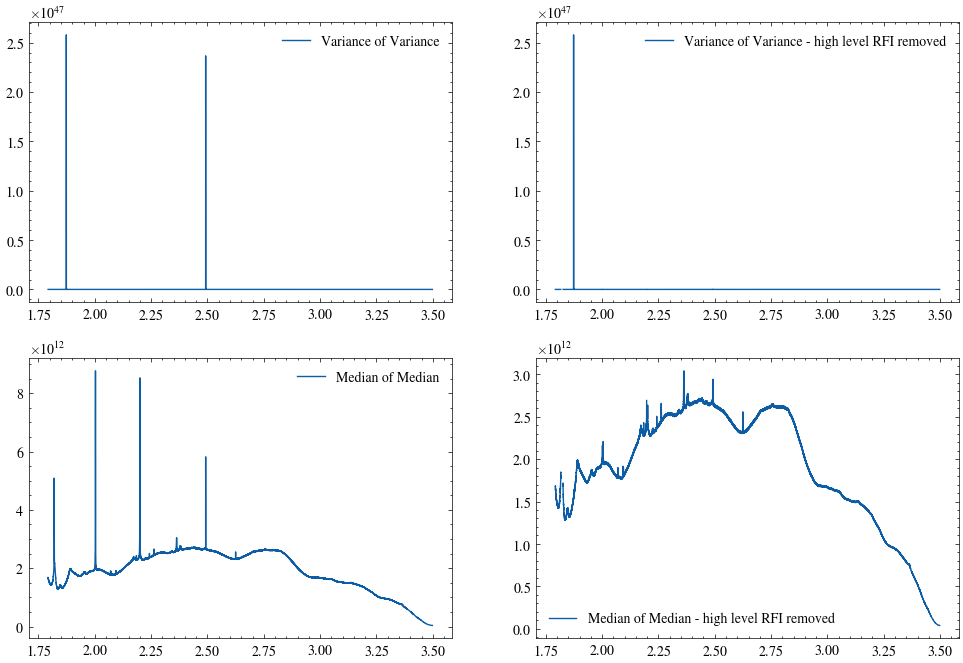

In [10]:
median_of_median_high = np.nanmedian(median_array_high, axis=0)
variance_of_variance_high = np.var(variance_array_high, axis=0)

#---- high level RFI removed
median_of_median_low = np.nanmedian(median_array_low, axis=0)
variance_of_variance_low = np.var(variance_array_low, axis=0)


fig, ax = plt.subplots(2,2,figsize=(12,8))

ax[0,0].plot(frequency, variance_of_variance_high, label='Variance of Variance')
ax[0,0].legend()


ax[1,0].plot(frequency, median_of_median_high, label='Median of Median')
ax[1,0].legend()


# high level RFI removed
ax[0,1].plot(frequency, variance_of_variance_low, label='Variance of Variance - high level RFI removed')
ax[0,1].legend()


ax[1,1].plot(frequency, median_of_median_low, label='Median of Median - high level RFI removed')
ax[1,1].legend()

### Perform the median square

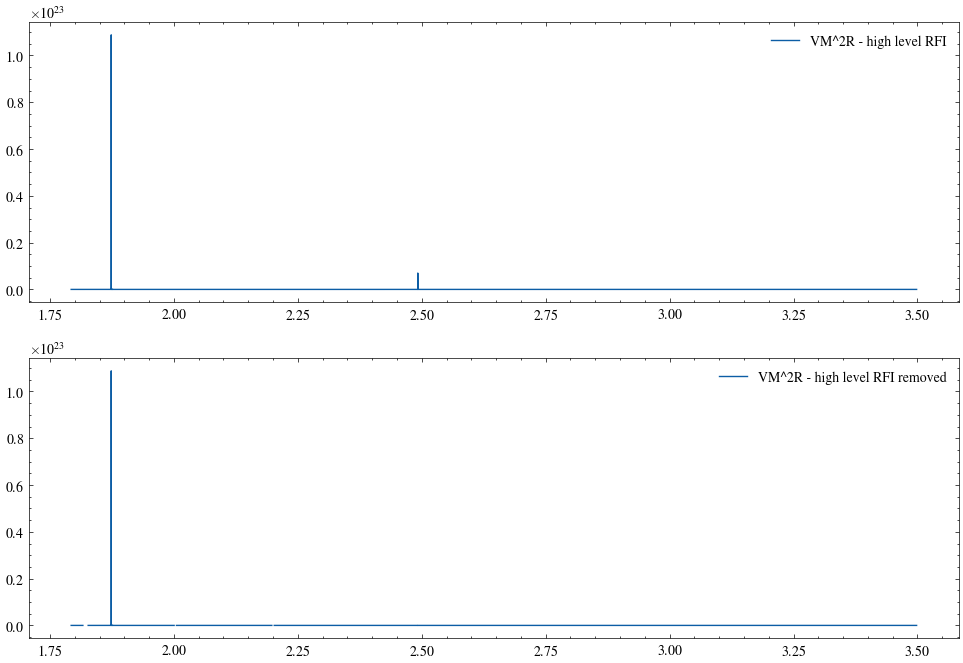

In [11]:
median_of_median_high_squared = (np.median(median_array_high, axis=0))**2

#---- high level RFI removed
median_of_median_low_squared = (np.median(median_array_low, axis=0))**2 


# perfom the VM^2R by dividing the variance of variance by the median of median squared
vm2r_high = variance_of_variance_high / median_of_median_high_squared
vm2r_low = variance_of_variance_low / median_of_median_low_squared


fig, ax = plt.subplots(2, 1,figsize=(12,8))

ax[0].plot(frequency, vm2r_high, label='VM^2R - high level RFI')
ax[0].legend()


ax[1].plot(frequency, vm2r_low, label='VM^2R - high level RFI removed')
ax[1].legend()



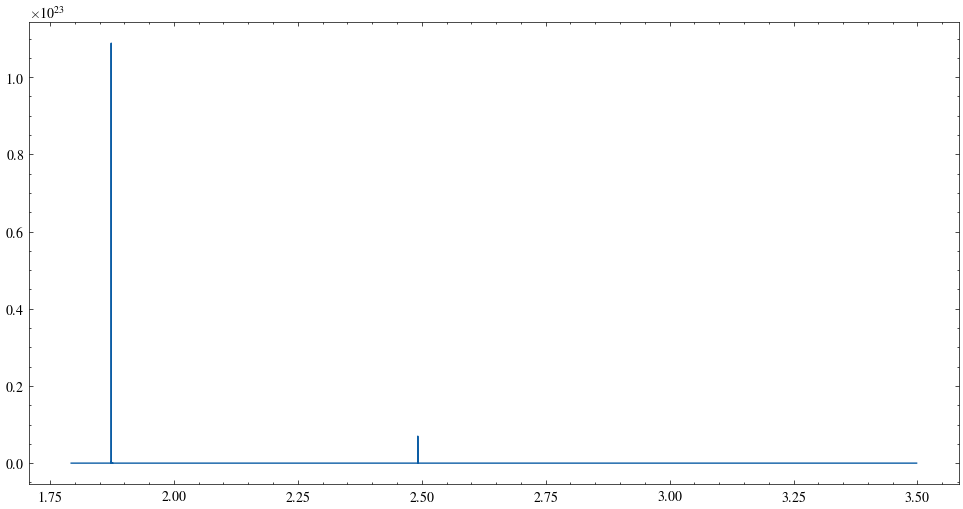

In [12]:
plt.figure(figsize=(12, 6))
plt.plot(frequency, vm2r_high, label='VM^2R')

In [13]:
# Perform median over time for each frequency channel
vm2r_median_high = np.nanmedian(vm2r_array_high, axis=0)
vm2r_median_low = np.nanmedian(vm2r_array_low, axis=0)

# Perform median over time for each frequency channel without taking in consideration the NAN
vm2r_median_low_nan = np.median(vm2r_array_low, axis=0)

/tmp/ipykernel_1926795/547601547.py:3: RuntimeWarning: All-NaN slice encountered
  vm2r_median_low = np.nanmedian(vm2r_array_low, axis=0)


[]

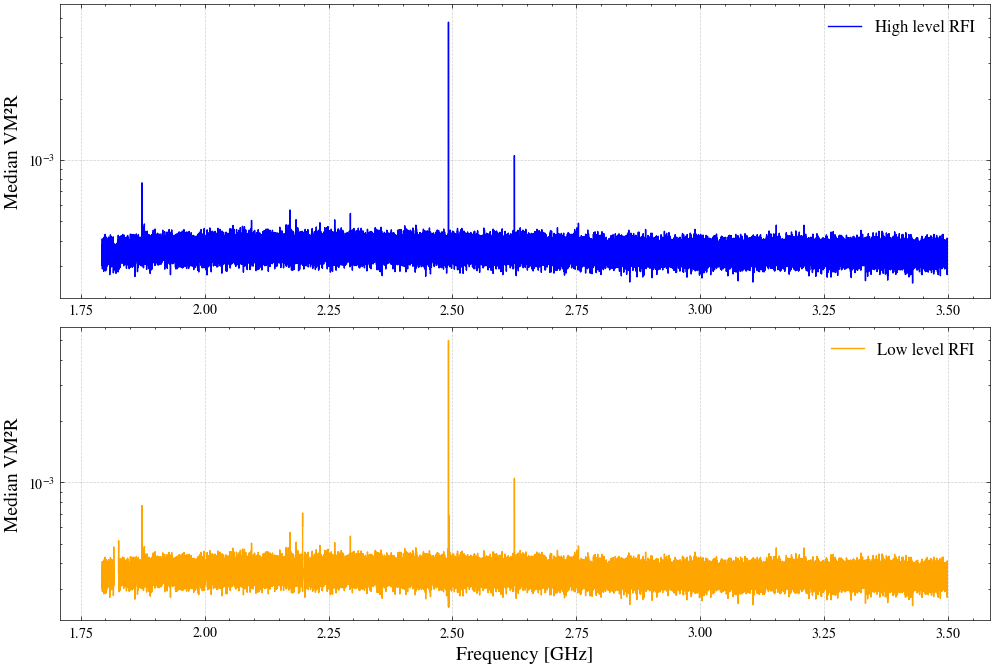

In [14]:
figure, ax = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
figure.subplots_adjust(hspace=0.1)
ax[0].plot(mask_frequency, vm2r_median_high, color='b', label='High level RFI')  
ax[0].set_ylabel("Median VM²R", fontsize=14)
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].legend(fontsize=12)
ax[0].semilogy()

ax[1].plot(mask_frequency, vm2r_median_low, color='orange', label='Low level RFI')
ax[1].set_xlabel("Frequency [GHz]", fontsize=14)
ax[1].set_ylabel("Median VM²R", fontsize=14)
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].legend(fontsize=12)
ax[1].semilogy()



